# LLM zero-shot ratings → title interest

**Idea.** Our 120 train labels are single-annotator ratings (very noisy), while the 30 test labels are means of
6 annotators. A large language model has read a lot of text written for and about readers, so its rating is a
reasonable proxy for an "average reader" — closer to what the 6-rater test mean measures.

**How the scores were made** (`llm_rate.py`, prompts saved in `features/llm_prompts.json`):
- model `mlx-community/Qwen2.5-VL-7B-Instruct-4bit` (**Apache-2.0**), run locally with mlx-vlm, text only;
- every train *and* test title is scored the same way, **zero-shot** — no labels are ever shown to the LLM, so the
  scores can be computed once and used inside CV without leakage;
- no sampling: we read the next-token probabilities of the digits 1–6 → expected rating (`interest_exp`, `click_exp`)
  and P(Yes) for five title traits the competition's annotators considered (curiosity gap, emotional language,
  exaggeration, direct address, missing details).

Then (fit only on `train.csv`, same 5-fold × 10-repeat CV as `baseline.ipynb`):
raw LLM rating → calibrated ridge → + traits → + mpnet embeddings → small MLP (neural net) → shrinkage → submissions.

In [1]:
import json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.linear_model import Ridge, HuberRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import mean_absolute_error

SEED = 42
random.seed(SEED); np.random.seed(SEED)

train = pd.read_csv("data/train.csv"); test = pd.read_csv("data/test.csv"); sample = pd.read_csv("data/sample_submission.csv")
llm = pd.read_csv("features/llm_scores.csv")
df = pd.concat([train, test], ignore_index=True).merge(llm, on="title_id", how="left")
assert df["interest_exp"].notna().all()
n = len(train)
tr_df = df.iloc[:n]
print(json.load(open("features/llm_prompts.json"))["rating_prompts"]["interest"])
df.filter(regex="title$|domain|interest$|_exp|_mass|trait_").head()

How interesting would a typical reader find this {kind} title?
Scale: 1 = not interesting at all, 2 = slightly, 3 = somewhat, 4 = fairly, 5 = very, 6 = extremely interesting.
Title: {title}
Answer with a single digit from 1 to 6.


,title,domain,interest,interest_mass,interest_exp,click_mass,click_exp,trait_curiosity_gap,trait_emotional,trait_exaggeration,trait_direct_address,trait_missing_details
0,"YFG Fatso - ""Bougie Hoes Pt 2 [Official Music ...",youtube,1.0,0.999450,3.787353,0.999513,3.200672,0.091382,0.144149,0.275130,0.001727,0.362969
1,RuneScape - Official 4th MMO Teaser Trailer,youtube,6.0,0.999836,4.290446,0.999784,4.191192,0.115961,0.000451,0.010987,0.000699,0.334589
2,We Found an ABANDONED AIRPLANE in Minecraft,youtube,1.0,0.999861,4.501854,0.999836,4.260986,0.418697,0.010014,0.177811,0.013428,0.523420
3,We Automate Infinite Netherite - Sky Factory S...,youtube,4.0,0.999789,4.007118,0.999774,3.868766,0.052619,0.000238,0.007461,0.000511,0.265880
4,How Hard Is Finding Bigfoot?,youtube,4.0,0.999838,4.066503,0.999872,3.756264,0.588889,0.003765,0.045353,0.031144,0.468791


## 1. Sanity checks and correlations with the (noisy) train labels

In [2]:
print("probability mass on the digits 1-6 (should be ~1):")
print(df[["interest_mass", "click_mass"]].describe().loc[["min", "mean"]].round(3))

feat = ["interest_exp", "click_exp"] + [c for c in df if c.startswith("trait_")]
rows = []
for c in feat:
    r = {"feature": c, "all": spearmanr(tr_df[c], tr_df.interest)[0]}
    for d, g in tr_df.groupby("domain"):
        r[d] = spearmanr(g[c], g.interest)[0]
    rows.append(r)
print("Spearman with interest on 120 train titles (|r| > ~0.18 overall / ~0.36 within a domain is significant)")
pd.DataFrame(rows).set_index("feature").round(3)

probability mass on the digits 1-6 (should be ~1):
      interest_mass  click_mass
min           0.999       0.998
mean          1.000       1.000
Spearman with interest on 120 train titles (|r| > ~0.18 overall / ~0.36 within a domain is significant)


,all,article,podcast,reddit,youtube
feature,,,,,
interest_exp,0.190,-0.059,0.357,0.337,0.231
click_exp,0.194,-0.254,0.278,0.320,0.386
trait_curiosity_gap,0.064,-0.202,0.127,0.259,0.118
trait_emotional,-0.048,-0.030,0.133,0.129,-0.312
trait_exaggeration,-0.072,-0.388,0.133,0.244,-0.021
trait_direct_address,-0.059,-0.068,0.319,-0.594,-0.050
trait_missing_details,-0.205,-0.213,-0.193,-0.286,-0.073


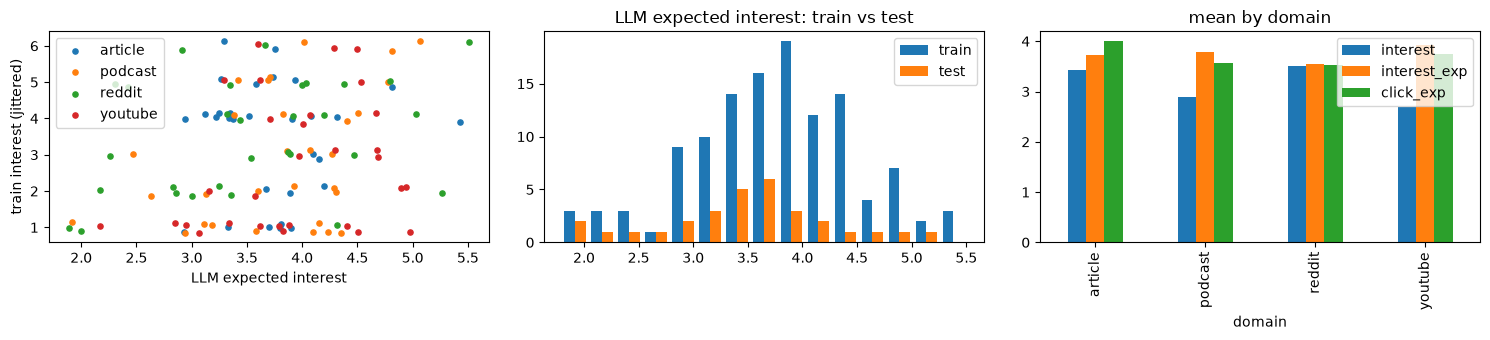

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
jit = np.random.default_rng(0).uniform(-.15, .15, n)
for d, g in tr_df.groupby("domain"):
    ax[0].scatter(g.interest_exp, g.interest + jit[g.index], s=14, label=d)
ax[0].set_xlabel("LLM expected interest"); ax[0].set_ylabel("train interest (jittered)"); ax[0].legend()
ax[1].hist([df.interest_exp[:n], df.interest_exp[n:]], bins=15, label=["train", "test"]); ax[1].legend()
ax[1].set_title("LLM expected interest: train vs test")
tr_df.groupby("domain")[["interest", "interest_exp", "click_exp"]].mean().plot.bar(ax=ax[2], title="mean by domain")
plt.tight_layout(); plt.show()

In [4]:
print("Highest and lowest LLM interest (train, with true single-rater label):")
for _, r in tr_df.sort_values("interest_exp").iloc[np.r_[0:5, -5:0]].iterrows():
    print(f"LLM {r.interest_exp:.2f} | label {r.interest:.0f} | [{r.domain}] {r.title[:85]}")

Highest and lowest LLM interest (train, with true single-rater label):
LLM 1.89 | label 1 | [reddit] just got home and filmed this to know how I looked
LLM 1.92 | label 1 | [podcast] BB28 Thursday Live Feed Update October 1, 2026
LLM 2.00 | label 1 | [reddit] The Senate. Upvote this so that people see it when they Google "The Senate".
LLM 2.17 | label 2 | [reddit] Thoughts on this?
LLM 2.17 | label 1 | [youtube] I Hate Clips...
LLM 5.03 | label 4 | [reddit] Japan is trialing a drug that regrows human teeth by blocking USAG-1—a protein that k
LLM 5.07 | label 6 | [podcast] Your Brain Is Begging for These 5 Things (And it could help you prevent Alzheimer’s d
LLM 5.26 | label 2 | [reddit] A terminally ill 5-year-old boy obsessed with horror movies found comfort in a Jason 
LLM 5.43 | label 4 | [article] Man accused of kidnapping woman he met on dating app, keeping her captive in attic fo
LLM 5.51 | label 6 | [reddit] TIL Napoleon III escaped from a fortress where he was serving a life sen

## 2. Cross-validation

Same splits and metric as `baseline.ipynb` (MAE vs single-annotator labels; pessimistic vs the 6-rater test means).
Reference: constant mean 1.495, mpnet SVR (run2) 1.466.

In [5]:
y = tr_df["interest"].values.astype(float)
cv = list(RepeatedKFold(n_splits=5, n_repeats=10, random_state=SEED).split(y))
N_REP = 10
results, oof = {}, {}

def evaluate(name, make_model, X):
    """Score one model with the shared repeated cross-validation (5 folds x 10 repeats = 50 splits).

    make_model: function that builds a NEW untrained model, e.g. lambda: Ridge(alpha=10).
                A fresh model per split guarantees nothing learned on one split leaks into another.
    X:          feature matrix for the 120 training titles (same row order as y).
    For every split: fit on ~96 titles, predict the ~24 held-out titles, clip to the valid range 1-6, compute MAE.
    Prints and stores mean +/- std of the 50 MAEs in `results[name]`.
    Also stores the out-of-fold predictions (shape: 10 repeats x 120 titles) so later cells can test
    shrinking predictions toward the mean, blending models, or correlations without refitting.
    """
    o = np.zeros((N_REP, n)); maes = []
    for k, (a, b) in enumerate(cv):
        p = np.clip(make_model().fit(X[a], y[a]).predict(X[b]), 1, 6)
        o[k // 5, b] = p; maes.append(mean_absolute_error(y[b], p))
    results[name] = dict(mae=np.mean(maes), std=np.std(maes)); oof[name] = o
    print(f"{name:45s} MAE {np.mean(maes):.3f} ± {np.std(maes):.3f}")

class Const:
    """Baseline 'model' that ignores the features and always predicts one number (the training mean).
    Every real model has to beat this reference point.
    """
    # remember the mean of the training labels
    def fit(self, X, y): self.c = y.mean(); return self
    # same value for every title
    def predict(self, X): return np.full(len(X), self.c)

class Raw:
    """Use column 0 (the LLM's expected rating) directly as the prediction, with no fitting.
    Shows how good the LLM is on its own, before a ridge maps it onto the label scale.
    """
    # nothing to learn
    def fit(self, X, y): return self
    # prediction = the raw LLM score
    def predict(self, X): return X[:, 0]

dom = pd.get_dummies(df["domain"]).values.astype(float)
traits = df[[c for c in df if c.startswith("trait_")]].values
probs = df[[f"interest_p{i}" for i in range(1, 7)] + [f"click_p{i}" for i in range(1, 7)]].values
A = df[["interest_exp"]].values
B = df[["interest_exp", "click_exp"]].values

X = {
    "raw": A,
    "llm1": np.hstack([A, dom]),
    "llm2": np.hstack([B, dom]),
    "llm2+traits": np.hstack([B, traits, dom]),
    "llm2+traits+probs": np.hstack([B, traits, probs, dom]),
}
evaluate("constant mean", Const, X["llm1"][:n])
evaluate("raw LLM interest_exp (no fit)", Raw, X["raw"][:n])
for k in ["llm1", "llm2", "llm2+traits", "llm2+traits+probs"]:
    for a in (1, 10, 30):
        evaluate(f"ridge {k} a={a}", lambda a=a: make_pipeline(StandardScaler(), Ridge(alpha=a)), X[k][:n])
evaluate("huber llm2+traits", lambda: make_pipeline(StandardScaler(), HuberRegressor(alpha=1, max_iter=1000)), X["llm2+traits"][:n])

constant mean                                 MAE 1.495 ± 0.174
raw LLM interest_exp (no fit)                 MAE 1.506 ± 0.144
ridge llm1 a=1                                MAE 1.415 ± 0.177
ridge llm1 a=10                               MAE 1.419 ± 0.176
ridge llm1 a=30                               MAE 1.426 ± 0.176
ridge llm2 a=1                                MAE 1.428 ± 0.177


ridge llm2 a=10                               MAE 1.428 ± 0.176


ridge llm2 a=30                               MAE 1.431 ± 0.176
ridge llm2+traits a=1                         MAE 1.469 ± 0.183
ridge llm2+traits a=10                        MAE 1.454 ± 0.181
ridge llm2+traits a=30                        MAE 1.443 ± 0.179
ridge llm2+traits+probs a=1                   MAE 1.504 ± 0.189


ridge llm2+traits+probs a=10                  MAE 1.466 ± 0.185


ridge llm2+traits+probs a=30                  MAE 1.449 ± 0.186
huber llm2+traits                             MAE 1.481 ± 0.185


### + mpnet title embeddings (as in the baseline)

In [6]:
import torch
from transformers import AutoTokenizer, AutoModel
torch.manual_seed(SEED)
DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"

def embed(texts, model_name="sentence-transformers/all-mpnet-base-v2", batch_size=32, max_length=128):
    """Turn each text into one sentence-embedding vector (frozen pretrained transformer, no training).

    Steps per batch:
      1. tokenize: split text into word pieces, pad to equal length (attention_mask = 1 for real tokens, 0 for padding)
      2. run the encoder -> last_hidden_state: one vector per token, shape (batch, tokens, hidden)
      3. mean pooling: average the token vectors, ignoring padding -> one vector per text
      4. L2-normalise to length 1, so only the direction (meaning) matters
    Returns a numpy array of shape (len(texts), hidden_size), e.g. 768 for mpnet/BERT.
    """
    tok = AutoTokenizer.from_pretrained(model_name)
    enc = AutoModel.from_pretrained(model_name).to(DEVICE).eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            b = tok(list(texts[i:i + batch_size]), padding=True, truncation=True, max_length=max_length,
                    return_tensors="pt").to(DEVICE)
            h = enc(**b).last_hidden_state; m = b["attention_mask"].unsqueeze(-1).float()
            out.append(torch.nn.functional.normalize((h * m).sum(1) / m.sum(1), dim=1).cpu().numpy())
    return np.vstack(out)

E = embed(df[["domain", "title"]].agg(": ".join, axis=1).values)
Z = StandardScaler().fit_transform(np.hstack([B, traits]))   # unsupervised scaling, no labels used
for w in (0.05, 0.1, 0.2):
    X[f"emb+llm w={w}"] = np.hstack([E, dom, Z * w])
    evaluate(f"SVR C=0.3 emb + llm w={w}", lambda: SVR(C=0.3, epsilon=0.5), X[f"emb+llm w={w}"][:n])
evaluate("SVR C=0.3 emb only (run2)", lambda: SVR(C=0.3, epsilon=0.5), np.hstack([E, dom])[:n])

/Users/home/workspace/School/ML/competition/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1122 00:58:03.972000 75968 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 18883.86it/s]

SVR C=0.3 emb + llm w=0.05                    MAE 1.465 ± 0.178
SVR C=0.3 emb + llm w=0.1                     MAE 1.462 ± 0.178


SVR C=0.3 emb + llm w=0.2                     MAE 1.457 ± 0.179
SVR C=0.3 emb only (run2)                     MAE 1.466 ± 0.178


### Small neural network (MLP) on the LLM features

A neural network can learn non-linear patterns that ridge cannot, so it is tested as an alternative. Inputs = LLM ratings + traits + domain (11 features),
standardised inside each fold; one hidden layer of 16, dropout, weight decay, fixed epochs, average of 5 seeds.

In [7]:
class TorchMLP:
    """Small neural network on the LLM features, averaged over 5 seeds.

    Features are standardised, the target is (label - mean). Each of the 5 networks
    (input -> 16 GELU units -> dropout -> 1) starts from a different seed; predictions are averaged,
    which reduces the randomness of training on only ~96 titles.
    """
    def __init__(self, hidden=16, dropout=0.2, wd=1e-2, epochs=200, lr=3e-3, seeds=(0, 1, 2, 3, 4)):
        """Store all hyper-parameters as attributes (self.hidden, self.seeds, ...)."""
        self.__dict__.update(locals()); del self.__dict__["self"]
    def fit(self, X, y):
        """Fit the scaler, then train one network per seed (AdamW, MSE, mini-batches of 16)."""
        self.sc = StandardScaler().fit(X); Xt = torch.tensor(self.sc.transform(X), dtype=torch.float32)
        self.mu = y.mean(); yt = torch.tensor(y - self.mu, dtype=torch.float32)
        self.nets = []
        for s in self.seeds:
            torch.manual_seed(SEED + s); g = torch.Generator().manual_seed(SEED + s)
            net = torch.nn.Sequential(torch.nn.Linear(X.shape[1], self.hidden), torch.nn.GELU(),
                                      torch.nn.Dropout(self.dropout), torch.nn.Linear(self.hidden, 1))
            opt = torch.optim.AdamW(net.parameters(), lr=self.lr, weight_decay=self.wd)
            for _ in range(self.epochs):
                net.train()
                for idx in torch.randperm(len(Xt), generator=g).split(16):
                    opt.zero_grad(); torch.nn.functional.mse_loss(net(Xt[idx]).squeeze(1), yt[idx]).backward(); opt.step()
            self.nets.append(net.eval())
        return self
    def predict(self, X):
        """Average the predictions of all seed networks and add the training mean back."""
        Xt = torch.tensor(self.sc.transform(X), dtype=torch.float32)
        with torch.no_grad():
            return np.mean([net(Xt).squeeze(1).numpy() for net in self.nets], 0) + self.mu

for ep, wd in [(50, 1e-2), (100, 1e-1), (200, 1e-1)]:
    evaluate(f"MLP llm2+traits ep={ep} wd={wd}", lambda ep=ep, wd=wd: TorchMLP(epochs=ep, wd=wd), X["llm2+traits"][:n])

MLP llm2+traits ep=50 wd=0.01                 MAE 1.463 ± 0.195


MLP llm2+traits ep=100 wd=0.1                 MAE 1.470 ± 0.203


MLP llm2+traits ep=200 wd=0.1                 MAE 1.474 ± 0.207


## 3. Results and shrinkage toward the mean

`pred = mean + s·(model − mean)`. Test targets are 6-rater means, so their spread is smaller than the single-rater
train labels; the s chosen on CV (against single ratings) is a reasonable, if rough, guide.

In [8]:
res = pd.DataFrame(results).T.sort_values("mae")
mu = y.mean(); s_grid = np.round(np.arange(0, 1.51, 0.1), 1)
top = [k for k in res.index if k != "constant mean"][:8]
shrink = pd.DataFrame({k: [np.mean([mean_absolute_error(y, mu + s * (oof[k][r] - mu)) for r in range(N_REP)]) for s in s_grid]
                       for k in top}, index=s_grid)
res["best_s"] = pd.Series({k: shrink[k].idxmin() for k in top})
res["mae_shrunk"] = pd.Series({k: shrink[k].min() for k in top})
res.round(3)

,mae,std,best_s,mae_shrunk
ridge llm1 a=1,1.415,0.177,1.2,1.413
ridge llm1 a=10,1.419,0.176,1.3,1.416
ridge llm1 a=30,1.426,0.176,1.4,1.421
ridge llm2 a=1,1.428,0.177,1.1,1.428
ridge llm2 a=10,1.428,0.176,1.2,1.427
ridge llm2 a=30,1.431,0.176,1.3,1.428
ridge llm2+traits a=30,1.443,0.179,0.8,1.441
ridge llm2+traits+probs a=30,1.449,0.186,0.8,1.448
ridge llm2+traits a=10,1.454,0.181,NaN,NaN
SVR C=0.3 emb + llm w=0.2,1.457,0.179,NaN,NaN


In [9]:
# Optimal shrink for 6-rater-mean targets, if we knew it: the test labels are less spread, so check how our
# predictions' spread compares with what a 6-rater mean would have (ICC from Webis was 0.38 for one rater).
for k in top[:3]:
    print(f"{k:45s} OOF pred std {oof[k].std():.2f} | train label std {y.std():.2f}")

ridge llm1 a=1                                OOF pred std 0.57 | train label std 1.68
ridge llm1 a=10                               OOF pred std 0.52 | train label std 1.68
ridge llm1 a=30                               OOF pred std 0.44 | train label std 1.68


## 4. Submissions

In [10]:
def fit_predict(make_model, Xall, s=1.0):
    """Fit on all 120 training titles (rows :n) and predict the 30 test titles (rows n:).
    s = shrink factor: final = mean + s * (prediction - mean); s = 1 keeps the prediction unchanged.
    Result is clipped to the valid range 1-6.
    """
    p = make_model().fit(Xall[:n], y).predict(Xall[n:])
    return np.clip(mu + s * (p - mu), 1, 6)

def write(fname, pred, label):
    """Save a Kaggle submission (title_id, interest) after checking that its columns and ids
    match sample_submission.csv exactly.
    """
    sub = pd.DataFrame({"title_id": test["title_id"], "interest": np.round(pred, 3)})
    assert list(sub.columns) == list(sample.columns) and set(sub.title_id) == set(sample.title_id) and len(sub) == 30
    sub.to_csv(fname, index=False)
    print(f"{fname:32s} {label} | pred range {pred.min():.2f}-{pred.max():.2f}")

lin = [k for k in res.index if k.startswith("ridge") or k.startswith("huber") or k.startswith("SVR C=0.3 emb + llm")]
best_lin = lin[0]
mlps = [k for k in res.index if k.startswith("MLP")]
best_mlp = mlps[0]
print("best linear:", best_lin, "| best MLP:", best_mlp)

def model_for(name):
    """Rebuild a model from its results-table name, e.g. 'ridge llm1 a=1' ->
    (model factory, matching full feature matrix), so the CV winner can be refit on all data.
    """
    if name.startswith("ridge"):
        key, a = name.split(" ")[1], float(name.split("a=")[-1])
        return (lambda: make_pipeline(StandardScaler(), Ridge(alpha=a))), X[key]
    if name.startswith("huber"):
        return (lambda: make_pipeline(StandardScaler(), HuberRegressor(alpha=1, max_iter=1000))), X["llm2+traits"]
    if name.startswith("SVR C=0.3 emb + llm"):
        return (lambda: SVR(C=0.3, epsilon=0.5)), X["emb+llm w=" + name.split("w=")[-1]]
    if name.startswith("MLP"):
        ep, wd = int(name.split("ep=")[1].split()[0]), float(name.split("wd=")[1])
        return (lambda: TorchMLP(epochs=ep, wd=wd)), X["llm2+traits"]

for fname, name in [("submission_llm_linear.csv", best_lin), ("submission_llm_mlp.csv", best_mlp)]:
    mk, Xall = model_for(name)
    s = 1.0   # CV-chosen s (1.1-1.3) gains <= 0.002 = noise; stretching is risky against smoother 6-rater test means
    write(fname, fit_predict(mk, Xall, s), f"{name} s={s} | CV MAE {res.loc[name, 'mae']:.3f}")

best linear: ridge llm1 a=1 | best MLP: MLP llm2+traits ep=50 wd=0.01
submission_llm_linear.csv        ridge llm1 a=1 s=1.0 | CV MAE 1.415 | pred range 2.23-4.15


submission_llm_mlp.csv           MLP llm2+traits ep=50 wd=0.01 s=1.0 | CV MAE 1.463 | pred range 2.05-4.41
